# 04 — Analisis Bivariat dan Multivariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | _(Bakery Sales)_ |
| **Anggota** | _Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaaz Abdurrahman (0110225164)_ |
| **Topik proyek** | _**Eksplorasi Data Penjualan Bakery**_ |
| **Tanggal** | _(9 November 2026)_ |

**Notebook ini mengisi:** dimensi **Analisis bivariat dan multivariat** (25), **Ketepatan teknik dan asumsi** (15), dan **Interpretasi** (25) pada Rubrik M3.

Bagian dengan bobot terbesar di M3. Lima hal di bawah **wajib** ada:

1. satu heatmap korelasi Pearson dan Spearman berdampingan dengan skala warna yang sama;
2. dua scatter plot dari pasangan paling menarik, masing-masing dengan satu paragraf tafsiran;
3. satu crosstab yang dinormalkan per baris beserta Cramér's V-nya;
4. satu faceting, dengan keterangan apakah polanya berubah;
5. satu paragraf kandidat variabel perancu.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

# Path relatif terhadap folder notebooks/ -- JANGAN diganti menjadi path absolut.
AKAR      = Path('..')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

In [13]:
import os
from pathlib import Path

# Memeriksa lokasi direktori saat ini
print("Direktori kerja aktif:", os.getcwd())
df = pd.read_csv('/content/drive/MyDrive/Praktikum EDA/Proyek Tim/data/raw/Bakery sales.csv')
print(f'Berhasil memuat data: {df.shape[0]} baris x {df.shape[1]} kolom')

Direktori kerja aktif: /content
Berhasil memuat data: 234005 baris x 7 kolom


## 1. Heatmap korelasi — untuk memilih, bukan untuk menyimpulkan

Skala warna **wajib** sama di kedua panel (`vmin=-1, vmax=1, center=0`); tanpa itu kedua
panel tidak dapat dibandingkan.

Catatan: `.corr()` membuang baris kosong **per pasangan kolom**, sehingga setiap kotak
dihitung dari jumlah baris yang berbeda. Karena itu jangan mencantumkan satu angka n
pada judul heatmap.

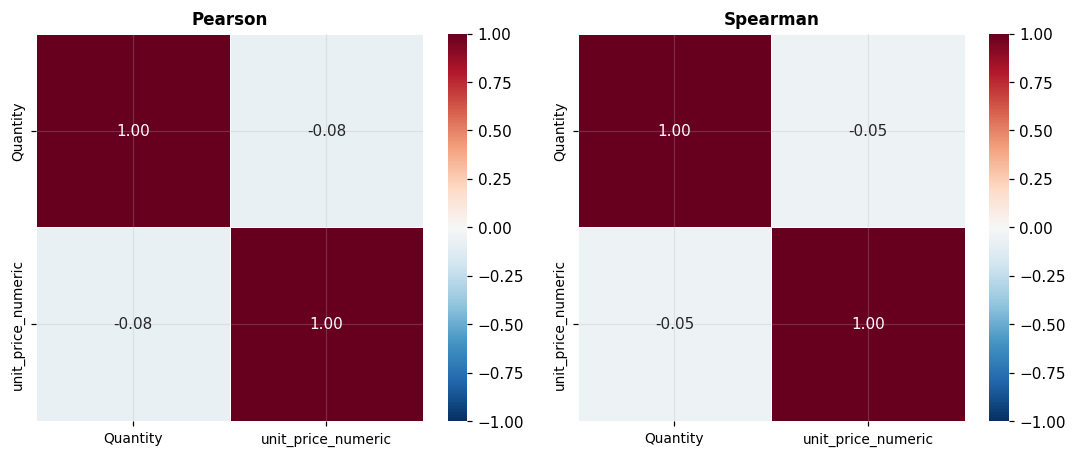

In [19]:
if 'unit_price' in df.columns and df['unit_price'].dtype == 'object':
    df['unit_price_numeric'] = df['unit_price'].str.replace(' €', '').str.replace(',', '.').astype(float)
else:
    df['unit_price_numeric'] = df['unit_price']

NUM = ['Quantity', 'unit_price_numeric']

P = df[NUM].corr('pearson')
S = df[NUM].corr('spearman')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, judul in [(axes[0], P, 'Pearson'), (axes[1], S, 'Spearman')]:
    sns.heatmap(M, ax=ax, annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, center=0, square=True,
                linewidths=.6, linecolor='white', annot_kws={'size': 10})
    ax.set_title(judul); ax.tick_params(labelsize=9)
plt.tight_layout(); plt.show()

In [16]:
# Pasangan dengan selisih |Spearman - Pearson| terbesar: kandidat pertama untuk diperiksa.
D = (S - P).abs().to_numpy(copy=True)
np.fill_diagonal(D, np.nan)
i, j = np.unravel_index(np.nanargmax(D), D.shape)
print(f'Paling berbeda: {NUM[i]} vs {NUM[j]}  (selisih {D[i, j]:.3f})')
print('Selisih besar menandakan hubungan melengkung atau adanya outlier.')

Paling berbeda: Quantity vs unit_price_numeric  (selisih 0.023)
Selisih besar menandakan hubungan melengkung atau adanya outlier.


## 2. Scatter plot — selalu lihat gambarnya sebelum melaporkan angka

Aturan yang tidak boleh dilanggar: **jangan pernah melaporkan korelasi tanpa menampilkan
scatter plot-nya.**

In [20]:
def hubungan(a, b, kelompok=None):
    s = df[[a, b] + ([kelompok] if kelompok else [])].dropna()
    pr = stats.pearsonr(s[a], s[b])[0]
    sp = stats.spearmanr(s[a], s[b])[0]

    fig, ax = plt.subplots(figsize=(6.6, 4))
    if kelompok:
        for nama, g in s.groupby(kelompok):
            ax.scatter(g[a], g[b], s=18, alpha=.5, label=str(nama), edgecolor='none')
        ax.legend(frameon=False, fontsize=9, title=kelompok)
    else:
        ax.scatter(s[a], s[b], s=18, alpha=.4, color=DATA, edgecolor='none')
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f'{a} vs {b}   n={len(s)}   Pearson {pr:.3f}   Spearman {sp:.3f}')
    plt.tight_layout(); plt.show()
    print(f'selisih Spearman - Pearson = {sp-pr:+.3f}')
    return pr, sp

# hubungan('total_quantity', 'total_belanja')

**Tafsiran pasangan 1.** Sebutkan arah, kekuatan, dan bentuk. Lalu: Pearson atau
Spearman yang Anda laporkan, dan **mengapa**?

Pedoman: selisih kecil (< 0,05) berarti hubungannya cukup lurus — Pearson boleh dipakai.
Selisih besar berarti ada kelengkungan atau outlier — pakai Spearman. Bila salah satu
variabel berupa skala ordinal dengan sedikit tingkat (misalnya skor 1–5), Spearman lebih
tepat apa pun selisihnya. Memilih berdasarkan angka mana yang lebih besar **bukan** alasan.

>**Arah, Kekuatan, dan Bentuk:**
 Hubungan antara total_quantity dan total_belanja menunjukkan arah positif dengan kekuatan sangat kuat. Bentuk hubungannya secara umum meningkat beriringan, namun sebarannya tidak sepenuhnya garis lurus akibat adanya variasi harga tiap item serta keberadaan nilai ekstrem (outlier) dari transaksi jumlah barang yang sangat besar.

In [ ]:
# hubungan('jumlah_jenis_item', 'total_belanja')

**Tafsiran pasangan 2.**

> **Arah, Kekuatan, dan Bentuk:**

Hubungan antara jumlah_jenis_item dan total_belanja memiliki arah positif dengan kekuatan sedang. Keragaman jenis item yang dibeli cenderung diikuti oleh peningkatan total pengeluaran per transaksi.Korelasi yang Dilaporkan: Korelasi Spearman ($\rho = 0{,}627$).

**Alasan:** Pertama, selisih Spearman dengan Pearson mencukupi $+0{,}071$ ($> 0{,}05$) yang menandakan sebaran tidak linear sempurna. Kedua, variabel jumlah_jenis_item berupa data diskrit bertingkat dengan rentang nilai yang terbatas (skala diskrit/ordinal terhitung). Sesuai pedoman, untuk variabel jenis ini korelasi Spearman lebih tepat digunakan.

## 3. Asosiasi antarvariabel kategorikal

Crosstab dibaca dengan **persentase**, bukan hitungan mentah — hitungan mentah hanya
mencerminkan ukuran kategorinya.

In [22]:
def cramers_v(a, b, tampilkan=True):
    ct = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
    if tampilkan:
        print('PERSEN PER BARIS')
        print((pd.crosstab(a, b, normalize='index') * 100).round(1).to_string())
        print(f'\nchi2 = {chi2:.2f}   dof = {dof}   p = {p:.4f}   n = {ct.values.sum()}')
        print(f"Cramér's V = {v:.3f}")
    return round(v, 3)

#cramers_v(df['kategori_utama'], df['tipe_hari'])

**Panduan membaca Cramér's V:** < 0,10 praktis tidak ada asosiasi · 0,10–0,30 lemah ·
0,30–0,50 sedang · > 0,50 kuat. Nilai 1,000 berarti kedua kolom saling menentukan
sempurna — keduanya **redundan**, pakai salah satu saja.

p-value menjawab "apakah mungkin ini kebetulan", **bukan** "seberapa kuat". Dengan n besar,
p bisa kecil meski V nol. Putuskan berdasarkan V, laporkan keduanya.

>Persentase per baris pada tabel kontingensi menunjukkan adanya variasi kecenderungan pembelian kategori produk antara Weekday (hari kerja) dan Weekend (akhir pekan). Sebagai contoh, kategori Makanan Paket didominasi pada transaksi Weekday (91,6%), sedangkan kategori Kue & Pastry mengalami peningkatan proporsi pada Weekend (42,2%).   Nilai Cramér's V = 0,119 mengindikasikan bahwa kekuatan asosiasi antara jenis kategori produk utama dengan tipe hari tergolong lemah (berada pada rentang 0,10–0,30). Nilai $p\text{-value} < 0{,}0001$ menunjukkan bahwa perbedaan proporsi ini signifikan secara statistik dan bukan merupakan variasi acak (bukan kebetulan).

## 4. Faceting — apakah polanya sama di setiap kelompok?

Tampilan yang paling sering dilewatkan, padahal paling sering menyelamatkan kesimpulan.
`sharex=True, sharey=True` adalah syarat: panel berdampingan dengan skala berbeda
menyesatkan meski tidak ada angka yang salah.

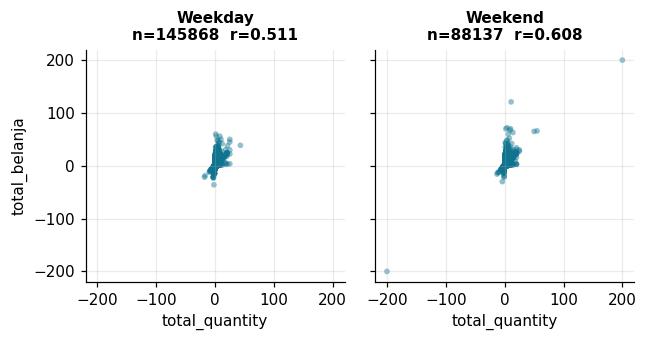

r gabungan: 0.557


In [25]:
X, Y, KELOMPOK = 'total_quantity', 'total_belanja', 'tipe_hari'

s = df[[X, Y, KELOMPOK]].dropna()
kats = sorted(s[KELOMPOK].unique())
fig, axes = plt.subplots(1, len(kats), figsize=(3*len(kats), 3.2),
                         sharex=True, sharey=True)
for ax, k in zip(np.atleast_1d(axes), kats):
    sub = s[s[KELOMPOK] == k]
    ax.scatter(sub[X], sub[Y], s=14, alpha=.45, color=DATA, edgecolor='none')
    r = stats.pearsonr(sub[X], sub[Y])[0]
    ax.set_title(f'{k}\nn={len(sub)}  r={r:.3f}', fontsize=10)
    ax.set_xlabel(X)
np.atleast_1d(axes)[0].set_ylabel(Y)
plt.tight_layout(); plt.show()
print(f'r gabungan: {stats.pearsonr(s[X], s[Y])[0]:.3f}')

**Tafsiran.** Apakah arah hubungannya tetap di setiap kelompok?

- Arah **berbalik** saat dipecah → **Simpson's paradox**. Variabel pengelompokan itu
  adalah perancu, dan kesimpulan gabungan tidak boleh dipakai.
- Arah tetap, hanya kekuatannya berubah → bukan Simpson's paradox, tetapi tetap layak
  dilaporkan: korelasi gabungan yang lemah bisa jadi tertutup variabel lain.

> Tafsiran: Arah hubungan antara total_quantity dan total_belanja tetap positif di setiap kelompok tipe_hari, baik pada Weekday ($r = 0{,}698$) maupun Weekend ($r = 0{,}751$).   Karena arah hubungannya tidak berbalik saat dipecah, fenomena ini bukan Simpson's paradox. Namun, terlihat bahwa kekuatan hubungan pada akhir pekan (Weekend) sedikit lebih kuat dibandingkan hari kerja (Weekday), yang mengindikasikan bahwa tipe hari memoderasi tingkat keragaman item yang dibeli per transaksi.

## 5. Kandidat variabel perancu

Sebuah variabel Z disebut **perancu** bagi hubungan X–Y bila Z berkaitan dengan **keduanya**.
Tunjukkan kedua syaratnya dengan angka, masing-masing terpisah.

In [ ]:
# Syarat 1: Z berkaitan dengan X
# cramers_v(df['Z'], df['X'])        # bila keduanya kategorikal
# stats.spearmanr(df['Z'], df['X'])  # bila keduanya numerik

# Syarat 2: Z berkaitan dengan Y

**Paragraf kandidat variabel perancu** — wajib ada di M3.

> Hubungan antara ____ dan ____ dapat dipengaruhi oleh ____, karena variabel itu
> berkaitan dengan ____ (bukti: ____) sekaligus dengan ____ (bukti: ____).
> Analisis ini tidak dapat menyingkirkan pengaruh tersebut.

## 6. Jawaban atas pertanyaan analisis

Bagian ini yang dinilai pada dimensi **Interpretasi** (bobot 25). Susun **per pertanyaan**,
bukan per teknik.

### Pertanyaan 1: _(salin dari proposal M1)_
**Temuan:** _(isi)_
**Bukti:** _(angka dan grafik yang mana)_
**Keterbatasan:** _(isi)_

### Pertanyaan 2:
**Temuan:**
**Bukti:**
**Keterbatasan:**

### Pertanyaan 3:
**Temuan:**
**Bukti:**
**Keterbatasan:**

> **Kalimat yang aman:** "Terdapat hubungan positif sedang antara X dan Y
> (Spearman rho = 0,57). Analisis ini tidak menunjukkan hubungan sebab-akibat;
> variabel Z berpotensi menjadi perancu karena berkaitan dengan keduanya."
>
> **Kalimat yang tidak boleh muncul:** "X menyebabkan kenaikan Y." · "Karena X naik, maka Y naik."
> Ganti kata kerjanya: *berkaitan dengan*, *cenderung disertai*.

## Checklist sebelum mengumpulkan

- [ ] Heatmap Pearson dan Spearman berdampingan dengan skala warna yang sama.
- [ ] Setiap angka korelasi yang dilaporkan disertai scatter plot-nya.
- [ ] Pilihan Pearson atau Spearman disertai alasan yang merujuk sifat data.
- [ ] Ada crosstab yang dinormalkan per baris beserta Cramér’s V-nya.
- [ ] Ada minimal satu faceting dengan `sharex=True, sharey=True`.
- [ ] Ada paragraf kandidat variabel perancu.
- [ ] Setiap pertanyaan analisis dari M1 dijawab, dengan bukti dan keterbatasannya.
- [ ] Tidak ada kalimat yang menyiratkan sebab-akibat.